In [89]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [90]:
def show_images(images):
    for name, image in images:
        cv.imshow(name, image)
    cv.waitKey(0)
    cv.destroyAllWindows()


Original size: (6000, 6000, 3)
Resized size: (720, 720, 3)
Loaded image data type: uint8
Image data types: 
	gray - uint8 
	rgb - uint8 
	xyz - uint8 
	lab - uint8 
	hsv - uint8 
	hls - uint8 
	ycrcb - uint8


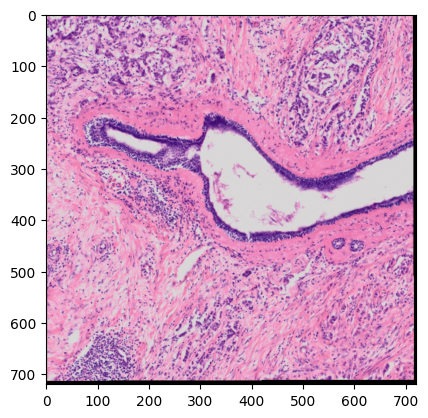

In [91]:
file1 = 'images/HMRegistred.png'
file2 = 'images/P63Registred.png'
file3 = 'images/Histology nuclei/TCGA-49-4488-01Z-00-DX1.tif'

# read image
img_uint8 = cv.imread(file1)
# convert to float
img_f32 = img_uint8.astype(np.float32) / 255.

img = img_uint8

# resize image
scale = 0.12
print('Original size:', img_uint8.shape)
img = cv.resize(img, (0, 0), fx=scale, fy=scale)
print('Resized size:', img.shape)
print('Loaded image data type:', img.dtype)

# convert to different color spaces
gray_img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
xyz_img = cv.cvtColor(img, cv.COLOR_BGR2XYZ)
lab_img = cv.cvtColor(img, cv.COLOR_BGR2LAB)
hsv_img = cv.cvtColor(img, cv.COLOR_BGR2HSV)
hls_img = cv.cvtColor(img, cv.COLOR_BGR2HLS)
ycrcb_img = cv.cvtColor(img, cv.COLOR_BGR2YCrCb)

# data types
print('Image data types:',
      '\n\tgray -', gray_img.dtype,
      '\n\trgb -', rgb_img.dtype,
      '\n\txyz -', xyz_img.dtype,
      '\n\tlab -', lab_img.dtype,
      '\n\thsv -', hsv_img.dtype,
      '\n\thls -', hls_img.dtype,
      '\n\tycrcb -', ycrcb_img.dtype)

# split channels
rgb_b, rgb_g, rgb_r = cv.split(img)
xyz_x, xyz_y, xyz_z = cv.split(xyz_img)
lab_l, lab_a, lab_b = cv.split(lab_img)
hsv_h, hsv_s, hsv_v = cv.split(hsv_img)
hls_h, hls_l, hls_s = cv.split(hls_img)
ycrcb_y, ycrcb_cr, ycrcb_cb = cv.split(ycrcb_img)

# show image
plt.imshow(rgb_img)

In [92]:
# create histogram for each channel

# GRAY
gray_hist = cv.calcHist([gray_img], [0], None, [256], [0, 256])

# RGB
rgb_r_hist = cv.calcHist([img], [0], None, [256], [0, 256])
rgb_g_hist = cv.calcHist([img], [1], None, [256], [0, 256])
rgb_b_hist = cv.calcHist([img], [2], None, [256], [0, 256])

# XYZ
xyz_x_hist = cv.calcHist([xyz_img], [0], None, [256], [0, 256])
xyz_y_hist = cv.calcHist([xyz_img], [1], None, [256], [0, 256])
xyz_z_hist = cv.calcHist([xyz_img], [2], None, [256], [0, 256])

# LAB
lab_l_hist = cv.calcHist([lab_img], [0], None, [256], [0, 256])
lab_a_hist = cv.calcHist([lab_img], [1], None, [256], [0, 256])
lab_b_hist = cv.calcHist([lab_img], [2], None, [256], [0, 256])

# HSV
hsv_h_hist = cv.calcHist([hsv_img], [0], None, [256], [0, 256])
hsv_s_hist = cv.calcHist([hsv_img], [1], None, [256], [0, 256])
hsv_v_hist = cv.calcHist([hsv_img], [2], None, [256], [0, 256])

# HLS
hls_h_hist = cv.calcHist([hls_img], [0], None, [256], [0, 256])
hls_l_hist = cv.calcHist([hls_img], [1], None, [256], [0, 256])
hls_s_hist = cv.calcHist([hls_img], [2], None, [256], [0, 256])

# YCrCb
ycrcb_y_hist = cv.calcHist([ycrcb_img], [0], None, [256], [0, 256])
ycrcb_cr_hist = cv.calcHist([ycrcb_img], [1], None, [256], [0, 256])
ycrcb_cb_hist = cv.calcHist([ycrcb_img], [2], None, [256], [0, 256])

In [93]:
# visualize each channels
rgb_channels = (
    ('RGB R', rgb_r),
    ('RGB G', rgb_g),
    ('RGB B', rgb_b),
)

xyz_channels = (
    ('XYZ X', xyz_x),
    ('XYZ Y', xyz_y),
    ('XYZ Z', xyz_z),
)

lab_channels = (
    ('LAB L', lab_l),
    ('LAB A', lab_a),
    ('LAB B', lab_b),
)

hsv_channels = (
    ('HSV H', hsv_h),
    ('HSV S', hsv_s),
    ('HSV V', hsv_v),
)

hls_channels = (
    ('HLS H', hls_h),
    ('HLS L', hls_l),
    ('HLS S', hls_s),
)

ycrcb_channels = (
    ('YCrCb Y', ycrcb_y),
    ('YCrCb Cr', ycrcb_cr),
    ('YCrCb Cb', ycrcb_cb),
)

In [94]:
show_images([
    # *rgb_channels,
    *xyz_channels,
    # *lab_channels,
    # *hsv_channels,
    # *hls_channels,
    # *ycrcb_channels,
])

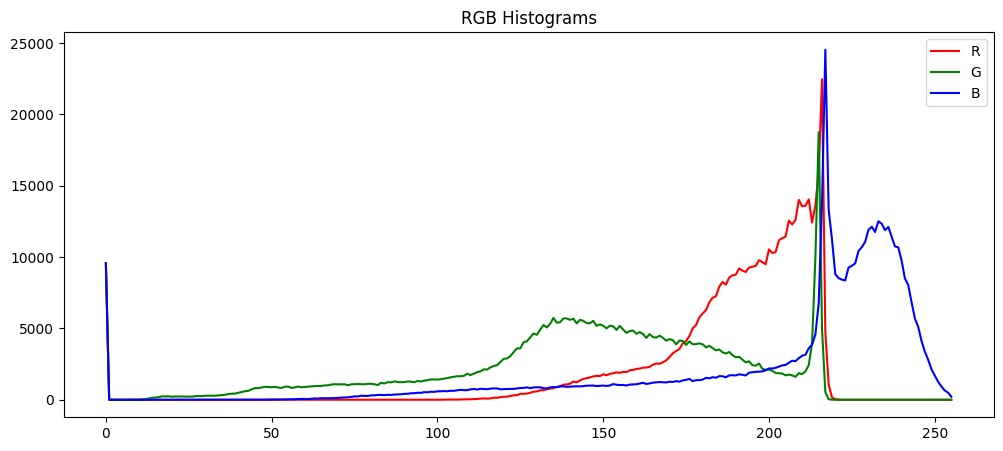

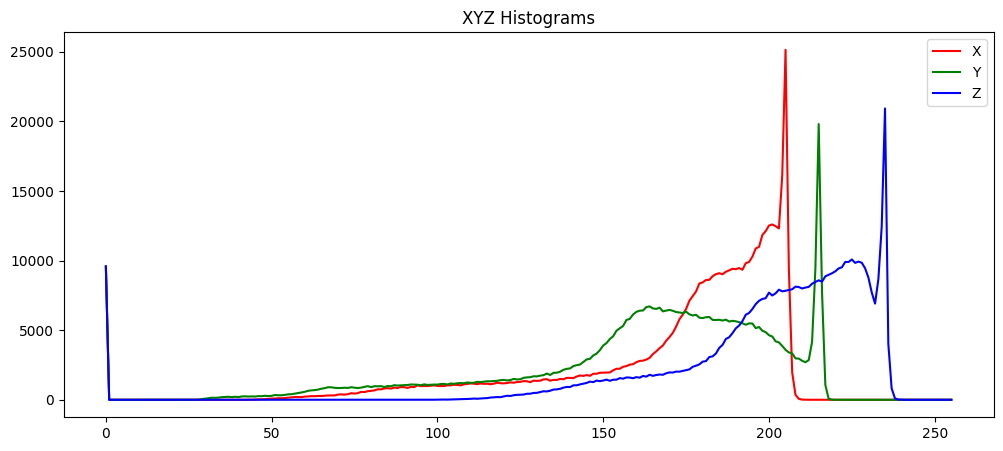

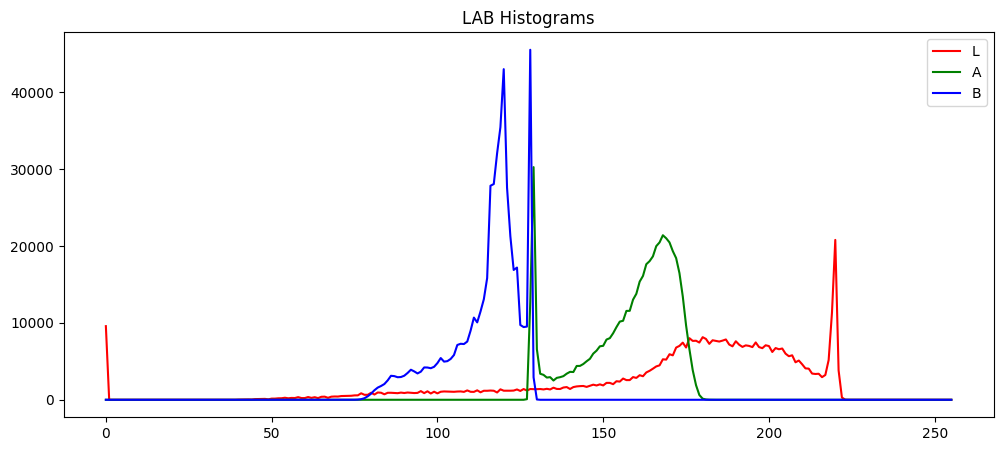

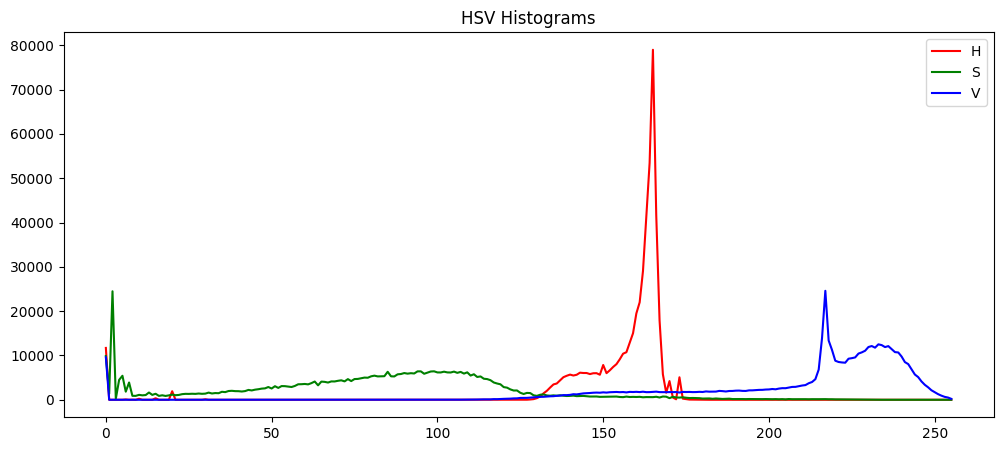

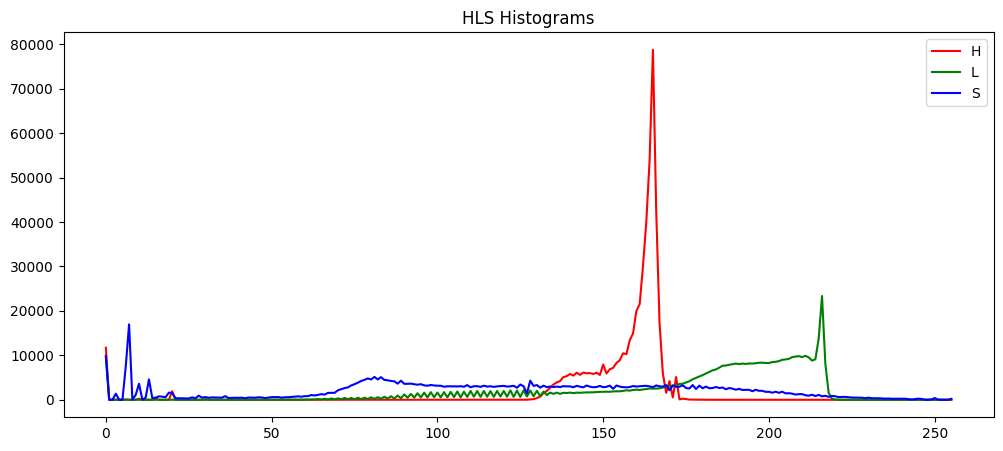

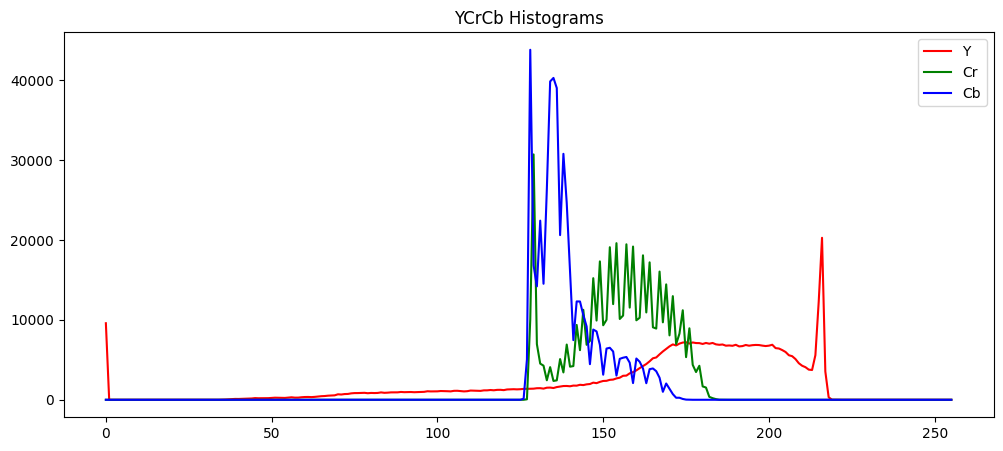

In [95]:
# plot histograms
plt.figure(figsize=(12, 5))
plt.title('RGB Histograms')
plt.plot(rgb_r_hist, color='red')
plt.plot(rgb_g_hist, color='green')
plt.plot(rgb_b_hist, color='blue')
plt.legend(['R', 'G', 'B'])
plt.show()

plt.figure(figsize=(12, 5))
plt.title('XYZ Histograms')
plt.plot(xyz_x_hist, color='red')
plt.plot(xyz_y_hist, color='green')
plt.plot(xyz_z_hist, color='blue')
plt.legend(['X', 'Y', 'Z'])
plt.show()

plt.figure(figsize=(12, 5))
plt.title('LAB Histograms')
plt.plot(lab_l_hist, color='red')
plt.plot(lab_a_hist, color='green')
plt.plot(lab_b_hist, color='blue')
plt.legend(['L', 'A', 'B'])
plt.show()

plt.figure(figsize=(12, 5))
plt.title('HSV Histograms')
plt.plot(hsv_h_hist, color='red')
plt.plot(hsv_s_hist, color='green')
plt.plot(hsv_v_hist, color='blue')
plt.legend(['H', 'S', 'V'])
plt.show()

plt.figure(figsize=(12, 5))
plt.title('HLS Histograms')
plt.plot(hls_h_hist, color='red')
plt.plot(hls_l_hist, color='green')
plt.plot(hls_s_hist, color='blue')
plt.legend(['H', 'L', 'S'])
plt.show()

plt.figure(figsize=(12, 5))
plt.title('YCrCb Histograms')
plt.plot(ycrcb_y_hist, color='red')
plt.plot(ycrcb_cr_hist, color='green')
plt.plot(ycrcb_cb_hist, color='blue')
plt.legend(['Y', 'Cr', 'Cb'])
plt.show()


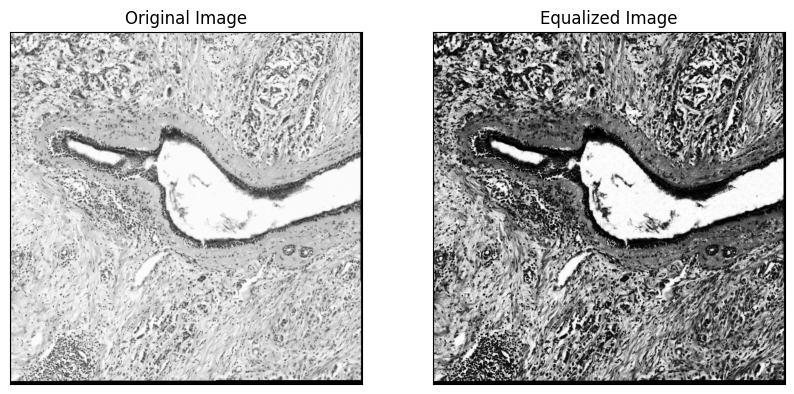

In [96]:
# Apply histogram equalization
equ = cv.equalizeHist(gray_img)

# plot images
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(gray_img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(equ, cmap='gray')
plt.title('Equalized Image'), plt.xticks([]), plt.yticks([])
plt.show()

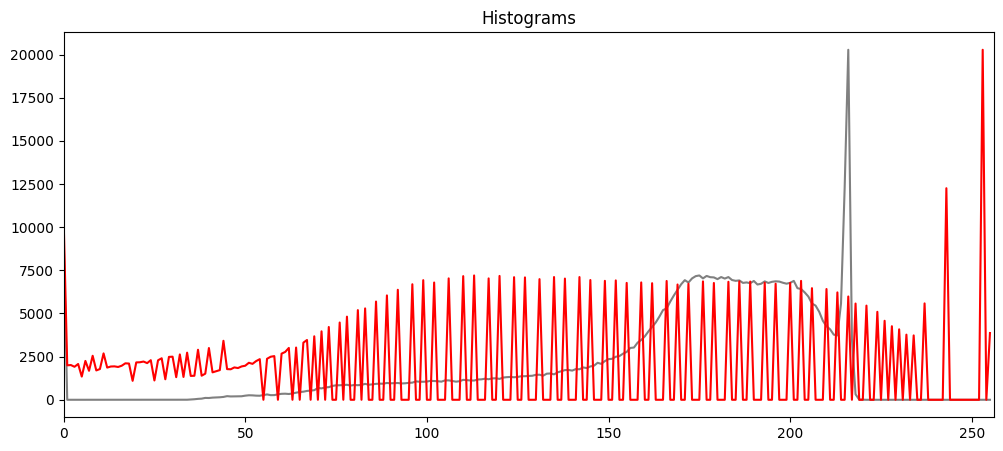

In [97]:
gray_hist = cv.calcHist([gray_img], [0], None, [256], [0, 256])
equ_hist = cv.calcHist([equ], [0], None, [256], [0, 256])

# plot histograms
plt.figure(figsize=(12, 5))
plt.title('Histograms')
plt.plot(gray_hist, color='gray')
plt.plot(equ_hist, color='red')
plt.xlim([0, 256])
plt.show()

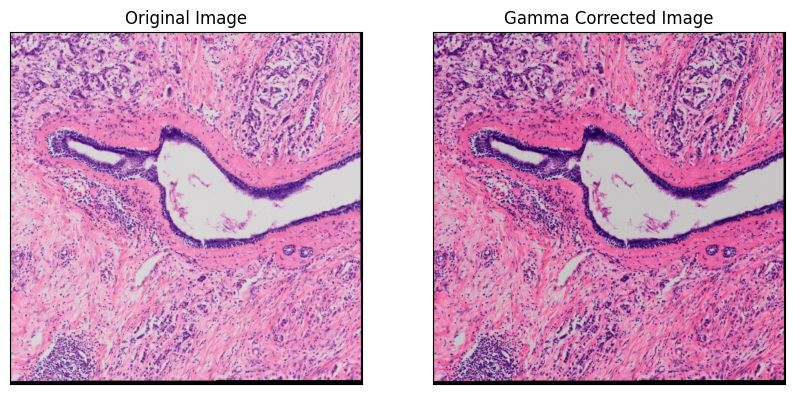

In [98]:
# Adjust the gamma value
gamma = 1.5
img_corrected = np.power(img / float(np.max(img)), gamma)
img_corrected = np.uint8(img_corrected * 255)

# Display the results
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv.cvtColor(img_corrected, cv.COLOR_BGR2RGB))
plt.title('Gamma Corrected Image'), plt.xticks([]), plt.yticks([])
plt.show()